# Timor-Leste: shared data preparation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gromicho/teaching/blob/main/foundations/cases/timor-leste-preparation.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/gromicho/teaching/main?urlpath=tree/foundations/cases/timor-leste-preparation.ipynb)

**Starter** · UvA Business Analytics teaching collection

Work through the questions before running each cell. Explain the result, check its assumptions, and change one input to test your understanding.


## Setup

Run the setup and data cells before timing either model. The notebook installs missing Python packages and provides two different optimization engines, CBC and HiGHS. Package installation and data loading are **not** part of model-instantiation or solving times. For local Jupyter use, see the [environment guidance](https://github.com/gromicho/teaching/blob/main/docs/SETUP.md).


## Inspect the facility-location case
This is the shared case workbook, not an instructor solution. Follow the ABW or AABW assignment for the particular model and questions. Sheet names, identifiers, units and distance conventions are part of the data contract; do not rely on row positions without checking their meaning.


In [9]:
# Load the shared teaching utilities from this checkout or a verified download.
from pathlib import Path
import hashlib
import sys
from urllib.request import urlopen

support_path = next((folder / 'support' for folder in [Path.cwd(), *Path.cwd().parents]
                     if (folder / 'support' / 'teaching_utils.py').is_file()), None)
if support_path is None:
    support_path = Path.cwd() / '.teaching-support'
    support_path.mkdir(exist_ok=True)
    helper = support_path / 'teaching_utils.py'
    expected = 'fbfa41e12709a01548e213abba976dad1e21d0abcfd798a2dfd669706cc152bb'
    if not helper.exists() or hashlib.sha256(helper.read_bytes()).hexdigest() != expected:
        url = 'https://raw.githubusercontent.com/gromicho/teaching/f3ad11b77cae7dd05315d314c7e72ee8516aaa3d/support/teaching_utils.py'
        content = urlopen(url, timeout=45).read()
        if hashlib.sha256(content).hexdigest() != expected:
            raise ValueError('Teaching helper version changed; reopen the current course notebook.')
        helper.write_bytes(content)
sys.path.insert(0, str(support_path))
from teaching_utils import ensure_packages

required_packages = {'openpyxl': 'openpyxl', 'pandas': 'pandas',
                     'matplotlib': 'matplotlib', 'pyomo': 'pyomo',
                     'highspy': 'highspy'}
ensure_packages(required_packages)


[]

In [10]:
from pathlib import Path
from urllib.request import urlopen
import hashlib

# Prefer the checked-in file locally; Colab downloads the same frozen edition.
data_path = next((p for p in [Path("data/cases/timor-leste.xlsx"), Path("timor-leste.xlsx")]
                 if p.is_file()), Path("timor-leste.xlsx"))
if not data_path.is_file():
    url = "https://raw.githubusercontent.com/gromicho/teaching/main/data/cases/timor-leste.xlsx"
    with urlopen(url, timeout=45) as response:
        payload = response.read()
    if hashlib.sha256(payload).hexdigest() != "31431b07df5b6797630b9ec5023f81aacd76d5bdab4e21cdd3d9fe4e129f021a":
        raise ValueError("Dataset checksum mismatch; do not use an unverified copy.")
    data_path.write_bytes(payload)
assert hashlib.sha256(data_path.read_bytes()).hexdigest() == "31431b07df5b6797630b9ec5023f81aacd76d5bdab4e21cdd3d9fe4e129f021a", "Unexpected local data version"


In [11]:
import pandas as pd
data = pd.read_excel(data_path,sheet_name=None,index_col=0)
for name,frame in data.items():
    print(name,frame.shape)
    display(frame.head())


Distances (1084, 94)


,0,1,2,3,4,5,6,7,8,9,...,84,85,86,87,88,89,90,91,92,93
0,25.282974,12.450111,21.443871,7.857896,15.916857,18.682854,11.368735,15.528705,6.462325,16.269198,...,13.176950,9.884427,14.447762,21.267580,0.670219,2.942796,8.508101,8.573995,21.178577,18.983836
1,25.283939,12.451135,21.444818,7.858674,15.917503,18.683527,11.369635,15.529484,6.463343,16.270166,...,13.177556,9.885188,14.448788,21.268451,0.670817,2.942153,8.508039,8.575030,21.179365,18.984787
2,12.405842,18.940875,14.859231,25.847805,24.233759,23.307280,22.120653,21.644902,24.798257,16.700960,...,25.442210,24.587590,17.010084,17.135001,30.709663,33.030609,32.883774,22.516016,19.909647,15.325604
3,12.213298,18.735474,14.649069,25.636978,24.110320,23.204619,21.907312,21.512860,24.597209,16.545732,...,25.301105,24.422650,16.802824,17.045930,30.511644,32.828428,32.670670,22.321125,19.826260,15.195588
4,12.430405,19.004113,14.898102,25.908086,24.301652,23.373083,22.178740,21.713447,24.863088,16.770440,...,25.511268,24.657019,17.072469,17.199128,30.775364,33.095078,32.942112,22.582451,19.972957,15.394032


Potential locations (94, 2)


,lat,lon
0,-8.897852,125.479268
1,-8.789767,125.424036
2,-8.861706,125.479025
3,-8.735311,125.460017
4,-8.754413,125.296622


Homes (1084, 2)


,lat,lon
0,-8.677321,125.418762
1,-8.677311,125.418763
2,-8.956048,125.382837
3,-8.954389,125.383877
4,-8.956665,125.382954


In [12]:
distances = data['Distances']
homes = data['Homes']
locations = data['Potential locations']

assert distances.index.equals(homes.index), 'Household identifiers differ.'
assert distances.columns.equals(locations.index), 'Facility identifiers differ.'
assert {'lon', 'lat'} <= set(homes.columns)
assert {'lon', 'lat'} <= set(locations.columns)
print(f'{len(homes)} households and {len(locations)} candidate facilities')


1084 households and 94 candidate facilities


## Before modelling
Identify household identifiers, candidate locations and the distance matrix. Check whether distance is measured along roads or as a straight line, and confirm the unit before using a service threshold. Inspect missing values and duplicate identifiers. Distinguish the number of covered households from the number of people they represent.

Then use the course's released questions to define the opening and coverage decisions, service threshold and facility limit. Do not guess these choices from a previous year's solved example.


## Solvers for the assignment

The earlier Drive starter suggested `appsi_cbc` and `appsi_highs`. This edition still provides the **CBC** and **HiGHS** engines. Its shared `make_solver` helper uses Pyomo's `cbcnl` interface for the packaged CBC binary, so use `make_solver(name)` with the names below rather than passing `"cbc"` directly to `pyo.SolverFactory`. The choice of interface does not supply or solve either assignment model. Compare solver times only after setup, and record the machine and software used.


In [13]:
import pyomo.environ as pyo
from teaching_utils import install_coin_solvers, make_solver

# Provides the CBC binary in Colab, Binder and local Jupyter environments.
install_coin_solvers()
solvers = ('cbc', 'appsi_highs')  # Distinct CBC and HiGHS engines.
for name in solvers:
    available = make_solver(name).available(exception_flag=False)
    print(f'{name}: {"available" if available else "unavailable"}')
    if not available:
        raise RuntimeError(f'Required assignment solver {name} is unavailable.')


cbc: available
appsi_highs: available


## Visualize the data and a future result

The plot below reproduces the **data overview** in the earlier Drive notebook. Once you have solved your models, call `ShowFacilityLocation` with `X` containing the identifiers of opened facility sites and `Z` containing the identifiers of covered households. The helper only draws the sets you supply; it does not compute an optimal solution.


In [14]:
import matplotlib.pyplot as plt

def ShowFacilityLocation(xHomes, yHomes, xFacilities, yFacilities, X=None, Z=None):
    """Plot candidate sites and households, optionally highlighting selected IDs."""
    home_points = pd.DataFrame({'lon': xHomes, 'lat': yHomes})
    facility_points = pd.DataFrame({'lon': xFacilities, 'lat': yFacilities})
    selected_sites = [] if X is None else list(X)
    covered_homes = [] if Z is None else list(Z)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.scatter(home_points['lon'], home_points['lat'], s=8, c='lightgray',
               label='Households')
    ax.scatter(facility_points['lon'], facility_points['lat'], s=35,
               marker='s', facecolors='none', edgecolors='tab:blue',
               label='Candidate sites')
    if covered_homes:
        covered = home_points.loc[covered_homes]
        ax.scatter(covered['lon'], covered['lat'], s=12, c='tab:green',
                   label='Covered households')
    if selected_sites:
        opened = facility_points.loc[selected_sites]
        ax.scatter(opened['lon'], opened['lat'], s=55, marker='s',
                   c='gold', edgecolors='black', label='Opened sites')
    ax.set(xlabel='Longitude', ylabel='Latitude', title='Timor-Leste facility-location data')
    ax.legend()
    plt.show()


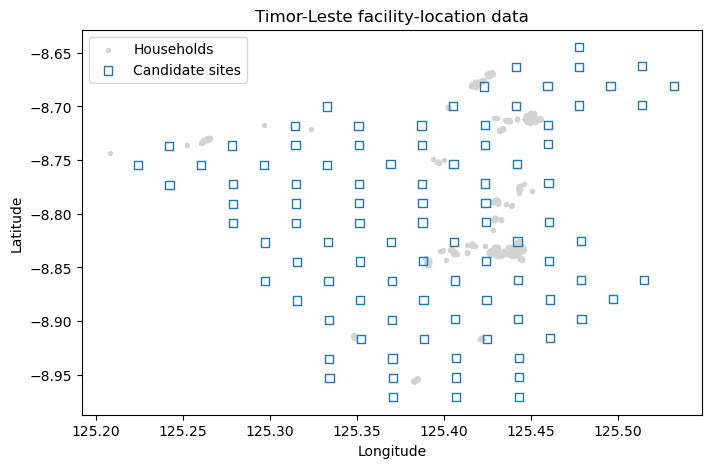

In [15]:
ShowFacilityLocation(homes['lon'], homes['lat'],
                     locations['lon'], locations['lat'])


Selected facility sites: [16, 34, 37, 45, 88]
Total households covered: 985 out of 1084


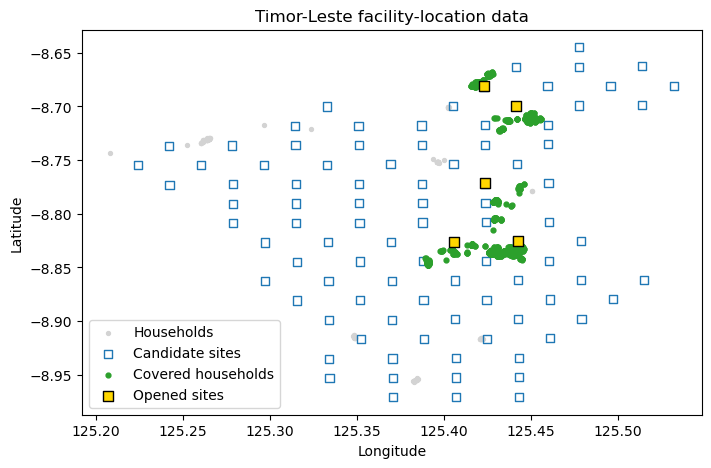

In [16]:
import pyomo.environ as pyo
from teaching_utils import make_solver

# 1. Define parameters and sets
new_facility_limit = 5          # Number of facilities to open
coverage_threshold = 3     # Service distance threshold in km

I = list(homes.index)       # Households
J = list(locations.index)   # Potential facility sites

# Precompute coverage: dij is 1 if facility j can cover household i
dij_less_then_coverage_threshold = {}
for i in I:
    for j in J:
        dij_less_then_coverage_threshold[i, j] = 1 if distances.at[i, j] <= coverage_threshold else 0

# Build the Pyomo Concrete Model
model = pyo.ConcreteModel(name="Maximal_Covering")

# Decision variables
model.xj = pyo.Var(J, domain=pyo.Binary)  # 1 if facility j is opened, 0 otherwise
model.zi = pyo.Var(I, domain=pyo.Binary)  # 1 if household i is covered, 0 otherwise
model.dij = pyo.Var(I , J, domain=pyo.NonNegativeIntegers)

# Objective using decorator
@model.Objective(sense=pyo.maximize)
def obj(model):
    return sum(model.zi[i] for i in I)

# Constraint: Maximum number of facilities to open (new_facility_limit >= sigma(j:J) Xj)
@model.Constraint()
def facility_limit(model):
    return sum(model.xj[j] for j in J) <= new_facility_limit

# Constraint: Household i can only be covered if at least one serving facility is opened (Zi <= Sigma(j:dij<=3)Xj)
@model.Constraint(I)
def coverage_con(model, i):
    return model.zi[i] <= sum(dij_less_then_coverage_threshold[i, j] * model.xj[j] for j in J)

# Solve the model using the appsi_highs solver
solver = make_solver('appsi_highs')
results = solver.solve(model)

# Extract results
opened_sites = [j for j in J if pyo.value(model.xj[j]) > 0.5]
covered_homes = [i for i in I if pyo.value(model.zi[i]) > 0.5]

print(f"Selected facility sites: {opened_sites}")
print(f"Total households covered: {len(covered_homes)} out of {len(I)}")

# Visualize the solution
ShowFacilityLocation(homes['lon'], homes['lat'],
                     locations['lon'], locations['lat'],
                     X=opened_sites, Z=covered_homes)